In [1]:
pip install rdkit

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/23.6 MB ? eta -:--:--
   ---- ----------------------------------- 2.6/23.6 MB 13.7 MB/s eta 0:00:02
   --------- ------------------------------ 5.8/23.6 MB 15.3 MB/s eta 0:00:02
   --------------- ------------------------ 9.2/23.6 MB 15.8 MB/s eta 0:00:01
   --------------------- ------------------ 12.6/23.6 MB 15.8 MB/s eta 0:00:01
   -------------------------- ------------- 15.5/23.6 MB 15.7 MB/s eta 0:00:01
   ------------------------------- -------- 18.6/23.6 MB 15.4 MB/s eta 0:00:01
   ------------------------------------ --- 21.8/23.6 MB 15.5 MB/s eta 0:00:01
   ---------------------------------------- 23.6/23.6 MB 15.1 MB/s  0:00:01
   ---------------------------------------- 0.0/15.9 MB ? eta -:--:--
   ------ --------------------------------- 2.6/15.9 MB 12.5 MB/s eta 0:00:02
   ------------- -------------------------- 5.5/15.9 MB 12.9 MB/s eta 0:00:01


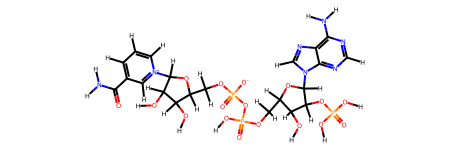

In [ ]:
# make sure you've installed rdkit, i usually use conda for environment control (conda install -c conda-forge rdkit)
# for the sake of this notebook though i just used pip to install rdkit

from rdkit import Chem
from rdkit.Chem import AllChem

#load the smiles and add hydrogens
#i used NADP+ as an example from the RCSB PDB page
#warning that this has a formal charge of 0, which doen't reflect actual molecule, it's just an example
smi = "NC(=O)c1ccc[n+](c1)[CH]2O[CH](CO[P]([O-])(=O)O[P](O)(=O)OC[CH]3O[CH]([CH](O[P](O)(O)=O)[CH]3O)n4cnc5c(N)ncnc45)[CH](O)[CH]2O"
molec = Chem.AddHs(Chem.MolFromSmiles(smi))

#show image of molecule
molec

embed status: 0


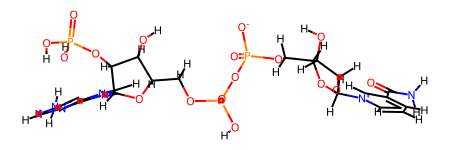

In [ ]:
#generate a conformer using the most recent stable version (v3) couldn't get v4 to work
params = AllChem.ETKDGv3()
params.randomSeed = 13
status = AllChem.EmbedMolecule(molec, params)

#conformer generation failed if it returns -1, succeeded if returns 0
print("embed status:", status)
#show updated molecular geometry
molec

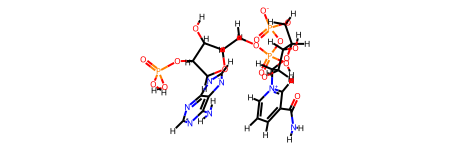

In [10]:
#optimize geometry with 5000 iterations
AllChem.MMFFOptimizeMolecule(molec, maxIters=5000)

#show optimized geometry
molec

In [18]:
#export as sdf file
Chem.MolToMolFile(molec, "NADP.sdf")
#print coordinates of top 10 atoms
coords = molec.GetConformer().GetPositions()
symbols = [atom.GetSymbol() for atom in molec.GetAtoms()]

for sym, (x, y, z) in list(zip(symbols,coords))[:10]:
    print(f'{sym:2s} {x:9.4f} {y:9.4f} {z:9.4f}')

N     3.7261   -3.8083    2.0574
C     3.5474   -2.5695    1.5144
O     4.0118   -1.5697    2.0543
C     2.7905   -2.4636    0.2446
C     1.9045   -3.4320   -0.2196
C     1.1521   -3.1656   -1.3606
C     1.2876   -1.9393   -2.0077
N     2.1795   -1.0239   -1.5687
C     2.9202   -1.2716   -0.4632
C     2.2127    0.3240   -2.1921
